   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                         

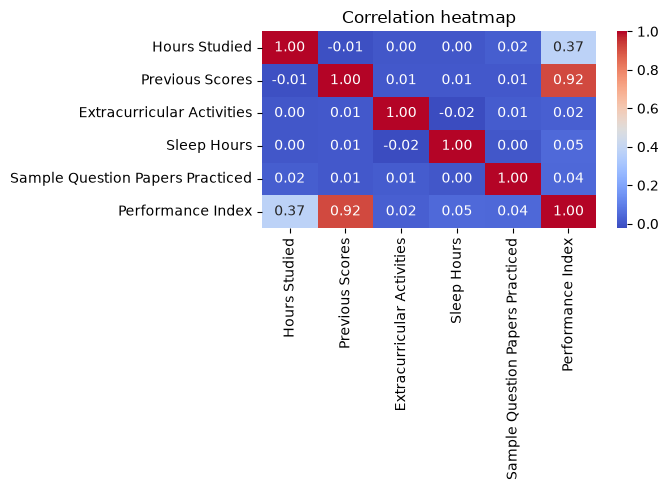


=== SIMPLE LINEAR REGRESSION ===
Intercept (b0): 41.43663482653576
Slope (b1): 2.7843004411707755
R2: 0.13160425385996788
RMSE: 17.93919001285204


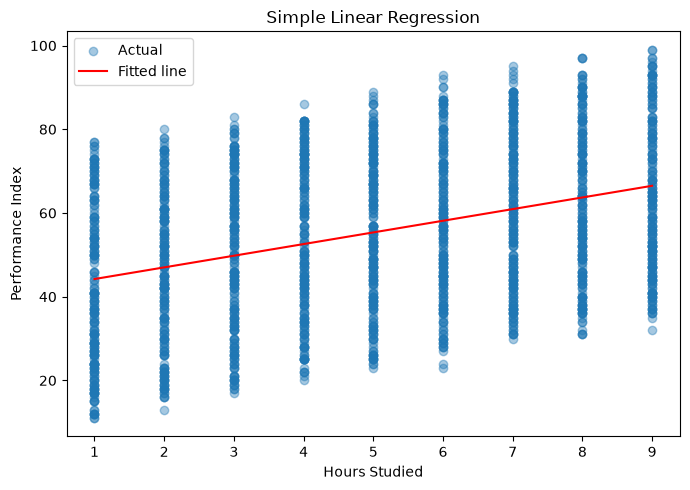


=== MULTIPLE LINEAR REGRESSION ===
Intercept: -33.92194621555629
Hours Studied                        2.8525
Previous Scores                      1.0170
Extracurricular Activities           0.6086
Sleep Hours                          0.4769
Sample Question Papers Practiced     0.1918
R2: 0.9889832909573145
Adjusted R2: 0.9889556663107681
RMSE: 2.020551508505006

                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:36:57   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
D

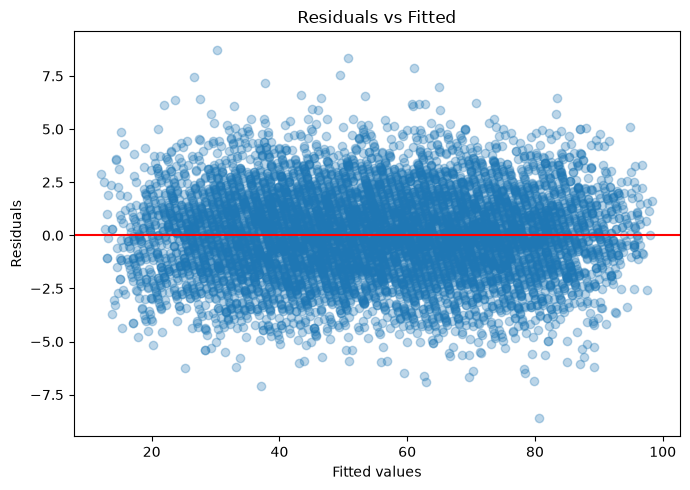

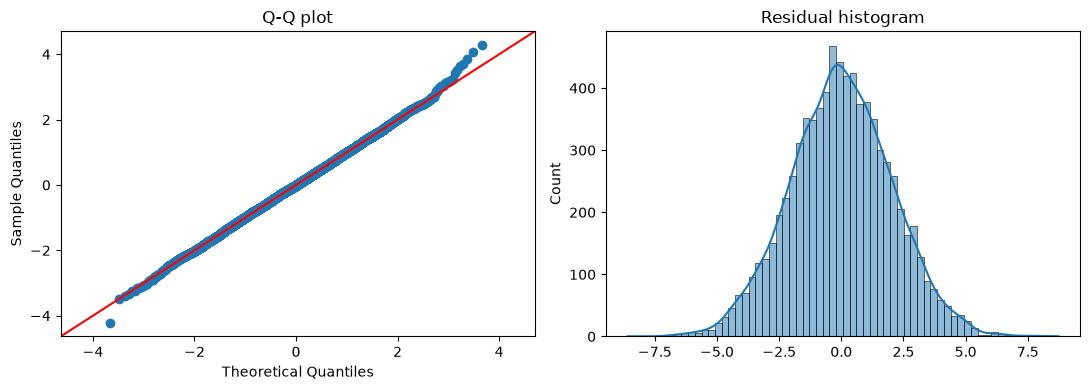

Breusch-Pagan p-value: 0.23962450879059718
Durbin-Watson: 2.033106022504011

VIF:
                             feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


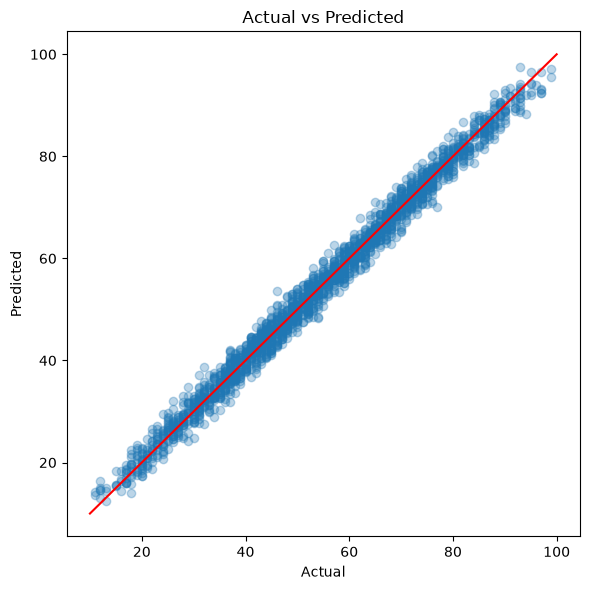

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

df = pd.read_csv(r"C:\Users\vbpat\Downloads\archive\Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

def split_data(X, y):
    indices = np.random.RandomState(42).permutation(len(X))
    test_size = int(np.ceil(len(X) * 0.2))
    test_idx = indices[:test_size]
    train_idx = indices[test_size:]
    return X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

def fit_linear_model(X):
    X_array = np.asarray(X, dtype=float)
    X_array = np.column_stack((np.ones(len(X_array)), X_array))
    return X_array

def predict_model(X, coefficients):
    return fit_linear_model(X) @ coefficients

def calculate_r2(actual, predicted):
    return 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2)

def calculate_rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

X_simple = df[["Hours Studied"]]
y = df["Performance Index"]

Xs_train, Xs_test, ys_train, ys_test = split_data(X_simple, y)

simple_coef = np.linalg.lstsq(fit_linear_model(Xs_train), ys_train, rcond=None)[0]

print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0):", simple_coef[0])
print("Slope (b1):", simple_coef[1])

ys_pred = predict_model(Xs_test, simple_coef)
print("R2:", calculate_r2(ys_test.to_numpy(), ys_pred))
print("RMSE:", calculate_rmse(ys_test.to_numpy(), ys_pred))

sorted_idx = Xs_test["Hours Studied"].sort_values().index
plt.figure(figsize=(7, 5))
plt.scatter(Xs_test["Hours Studied"], ys_test, alpha=0.4, label="Actual")
plt.plot(
    Xs_test.loc[sorted_idx, "Hours Studied"],
    predict_model(Xs_test.loc[sorted_idx], simple_coef),
    color="red",
    label="Fitted line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = split_data(X, y)

multi_coef = np.linalg.lstsq(fit_linear_model(X_train), y_train, rcond=None)[0]

print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept:", multi_coef[0])

for name, coef in zip(X.columns, multi_coef[1:]):
    print(f"{name:35s} {coef: .4f}")

y_pred = predict_model(X_test, multi_coef)
r2 = calculate_r2(y_test.to_numpy(), y_pred)
rmse = calculate_rmse(y_test.to_numpy(), y_pred)
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2:", r2)
print("Adjusted R2:", adj_r2)
print("RMSE:", rmse)

X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print("\n", ols.summary())

fitted = ols.fittedvalues
resid = ols.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)
print("Durbin-Watson:", durbin_watson(resid))

vif = pd.DataFrame({
    "feature": X_train_sm.columns,
    "VIF": [
        variance_inflation_factor(X_train_sm.values, i)
        for i in range(X_train_sm.shape[1])
    ]
})
print("\nVIF:\n", vif[vif["feature"] != "const"])

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()
